In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [3]:
import io

filename = next(iter(uploaded))

df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    encoding="latin1"
)

print("Dataset shape:", df.shape)
display(df.head())
print(df.info())

Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [4]:
df.columns = df.columns.str.strip()

df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

for col in ["Sales", "Profit", "Discount", "Quantity"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
df = df.dropna(subset=["Sales", "Profit", "Region", "Category"])

print("Cleaned dataset shape:", df.shape)

Missing values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicate rows: 0
Cleaned dataset shape: (9994, 21)


In [5]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
profit_margin = (
    total_profit / total_sales * 100
    if total_sales != 0 else 0
)

print(f"Total sales: ${total_sales:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Unique orders: {total_orders:,}")
print(f"Profit margin: {profit_margin:.2f}%")

Total sales: $2,297,200.86
Total profit: $286,397.02
Unique orders: 5,009
Profit margin: 12.47%


In [6]:
conn = sqlite3.connect(":memory:")

df.to_sql("orders", conn, index=False, if_exists="replace")

query = """
SELECT
    Region,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit
FROM orders
GROUP BY Region
ORDER BY total_profit DESC;
"""

region_results = pd.read_sql_query(query, conn)
display(region_results)

,Region,total_sales,total_profit
0,West,725457.82,108418.45
1,East,678781.24,91522.78
2,South,391721.91,46749.43
3,Central,501239.89,39706.36


In [7]:
category_results = pd.read_sql_query("""
SELECT
    Category,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit
FROM orders
GROUP BY Category
ORDER BY total_profit DESC;
""", conn)

display(category_results)

,Category,total_sales,total_profit
0,Technology,836154.03,145454.95
1,Office Supplies,719047.03,122490.80
2,Furniture,741999.80,18451.27


In [8]:
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0, 0.10, 0.20, 0.40, 1.0],
    labels=[
        "No discount",
        "0-10%",
        "10-20%",
        "20-40%",
        "40%+"
    ]
)

discount_results = (
    df.groupby("Discount Band", observed=False)
      .agg(
          transactions=("Profit", "size"),
          average_sales=("Sales", "mean"),
          average_profit=("Profit", "mean")
      )
      .round(2)
)

display(discount_results)

,transactions,average_sales,average_profit
Discount Band,,,
No discount,4798,226.74,66.90
0-10%,94,578.40,96.06
10-20%,3709,213.58,24.74
20-40%,460,509.00,-77.86
40%+,933,137.87,-106.71


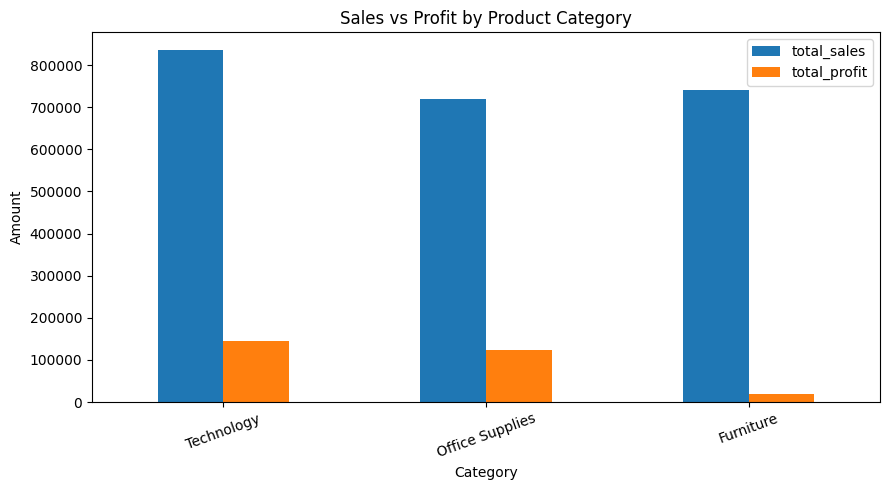

In [9]:
category_results.plot(
    x="Category",
    y=["total_sales", "total_profit"],
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sales vs Profit by Product Category")
plt.ylabel("Amount")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

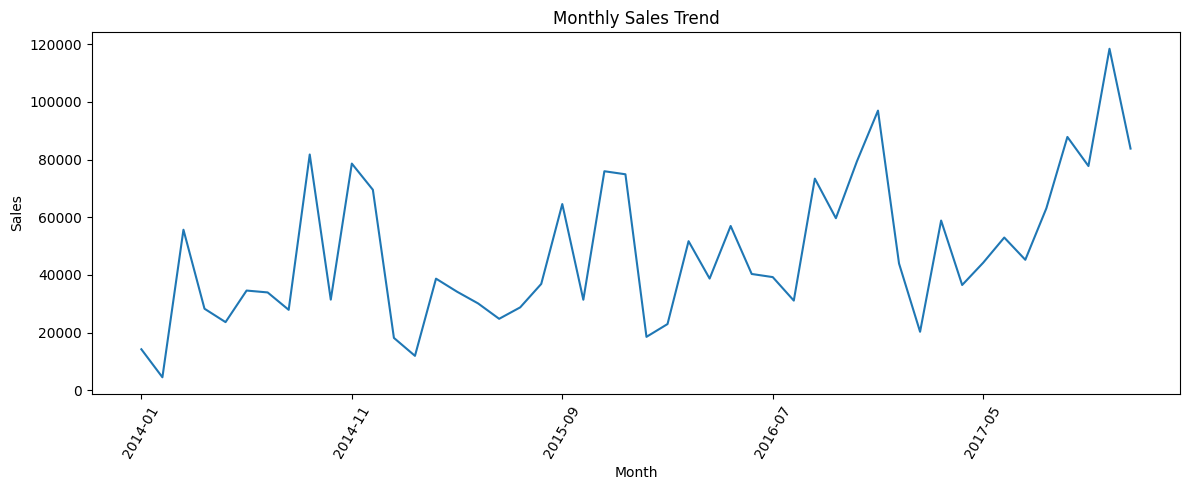

In [10]:
df["Order Month"] = df["Order Date"].dt.to_period("M").astype(str)

monthly_sales = (
    df.groupby("Order Month")["Sales"]
      .sum()
      .sort_index()
)

monthly_sales.plot(figsize=(12, 5))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

In [11]:
subcategory_results = pd.read_sql_query("""
SELECT
    Category,
    "Sub-Category" AS sub_category,
    ROUND(SUM(Sales), 2) AS total_sales,
    ROUND(SUM(Profit), 2) AS total_profit
FROM orders
GROUP BY Category, "Sub-Category"
HAVING SUM(Profit) < 0
ORDER BY total_profit ASC;
""", conn)

display(subcategory_results)

,Category,sub_category,total_sales,total_profit
0,Furniture,Tables,206965.53,-17725.48
1,Furniture,Bookcases,114880.00,-3472.56
2,Office Supplies,Supplies,46673.54,-1189.10


In [12]:
conn.close()
print("Analysis completed.")

Analysis completed.
